# Clustering of the Data

In [98]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN


DATA_PATH = Path(r"NREL_DEL.csv")

In [2]:
# Preview the data
df = pd.read_csv(DATA_PATH)
print(df.head())

         Hs        Tp    Vw_mean    Vw_std        RPM      Pitch  \
0  1.248500  4.757716   9.203143  1.749217   9.972552   0.019171   
1  1.574769  6.303943  11.370682  1.839102  11.694177   1.296207   
2  0.895745  5.364305  11.460520  1.651695  11.757063   1.184234   
3  0.638518  7.412787   6.598440  1.438964   8.256958   0.000000   
4  2.740453  5.828636  15.811478  2.406468  12.093967  10.479204   

            DEL  operating_state  
0  1.460472e+06                0  
1  1.733923e+06                0  
2  1.831648e+06                0  
3  8.610574e+05                0  
4  2.552811e+06                0  


In [3]:
# Load the data into variables
Hs = df["Hs"].values
Tp = df["Tp"].values
Vw_mean = df["Vw_mean"].values
Vw_std = df["Vw_std"].values
RPM = df["RPM"].values
Pitch = df["Pitch"].values
DEL = df["DEL"].values
operating_state = df["operating_state"].values

In [12]:
# Load the ml model results
df_ml_results = pd.read_csv("ml_results.csv", index_col=0)
best_model = df_ml_results.iloc[1]
print(f"Best model: {best_model['Model']}, R2: {best_model['R²']}, MAE: {best_model['MAE']}, RMSE: {best_model['RMSE']}")

Best model: Random Forest, R2: 0.9666430268492888, MAE: 84352.02673617261, RMSE: 115451.31337222946


## Prepare the clustering features

K-means uses Euclidean distance, so the environmental variables are standardised first. The direction is converted to two periodic coordinates; the original direction is retained for reporting.

In [ ]:
feature_columns = ["Hs", "Tp", "Vw_mean", "Vw_std", "RPM", "Pitch"]

In [16]:
X = df[["Hs", "Tp", "Vw_mean"]].copy()
scaler = StandardScaler()
features = scaler.fit_transform(X)

## Method 1: K-Means 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


def cluster_operating_state(df, state, feature_columns=None, state_column="operating_state", random_state=100, max_k=12, show_plots=True,):
    """ Perform K-means clustering on a selected operating state. """


    feature_columns = ["Hs","Tp", "Vw_mean","Vw_std","RPM","Pitch"]

    # --------------------------------------------------
    # Filter chosen operating state
    # --------------------------------------------------
    df_state = (df.loc[df[state_column] == state].copy().reset_index(drop=True))
    df_state = df_state.dropna(subset=feature_columns)

    # --------------------------------------------------
    # Scale features
    # --------------------------------------------------
    scaler = StandardScaler()
    X = scaler.fit_transform(df_state[feature_columns])

    # --------------------------------------------------
    # Find optimal k
    # --------------------------------------------------
    candidate_k = range(2,min(max_k, len(df_state) - 1) + 1)

    silhouette_scores = []

    for k in candidate_k:
        model = KMeans(n_clusters=k,n_init=20,random_state=random_state )
        labels = model.fit_predict(X)
        score = silhouette_score(X, labels)
        silhouette_scores.append(score)

    selection = pd.DataFrame({"k": list(candidate_k),"silhouette": silhouette_scores,})
    selected_k = int(selection.loc[selection["silhouette"].idxmax(), "k" ])

    # --------------------------------------------------
    # Final K-means
    # --------------------------------------------------
    kmeans = KMeans(n_clusters=selected_k, n_init=50, random_state=random_state)
    df_state["cluster"] = kmeans.fit_predict(X)

    # --------------------------------------------------
    # Representative states
    # --------------------------------------------------

    centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=feature_columns,)
    probabilities = (df_state["cluster"].value_counts(normalize=True).sort_index())
    centers["occurrence_probability"] = (probabilities.values)
    centers["cluster"] = np.arange(selected_k)
    centers = (centers.sort_values("Vw_mean").reset_index(drop=True))

    # --------------------------------------------------
    # Plotting
    # --------------------------------------------------

    if show_plots:
        fig, axes = plt.subplots(1, 3, figsize=(16, 4))

        # Silhouette
        axes[0].plot(selection["k"],selection["silhouette"],marker="o")
        axes[0].axvline(selected_k,color="red",linestyle="--")
        axes[0].set(xlabel="Number of clusters (k)",ylabel="Silhouette score",title=f"State {state}: chosen k={selected_k}")

        # Cluster map
        axes[1].scatter(df_state["Vw_mean"],df_state["Hs"],c=df_state["cluster"],cmap="tab10",s=8,alpha=0.35)
        axes[1].scatter(centers["Vw_mean"],centers["Hs"],color="black",marker="x",s=80)

        axes[1].set(xlabel="Mean wind speed (m/s)",ylabel="Hs (m)", title="Representative states")

        # Occurrence
        axes[2].bar(np.arange(len(centers)), centers["occurrence_probability"])
        axes[2].set( xlabel="Representative state",ylabel="Occurrence probability", title="Cluster probability")

        plt.tight_layout()
        plt.show()

    return {
        "data": df_state,
        "centers": centers,
        "selection": selection,
        "selected_k": selected_k,
        "kmeans": kmeans,
        "scaler": scaler,
    }

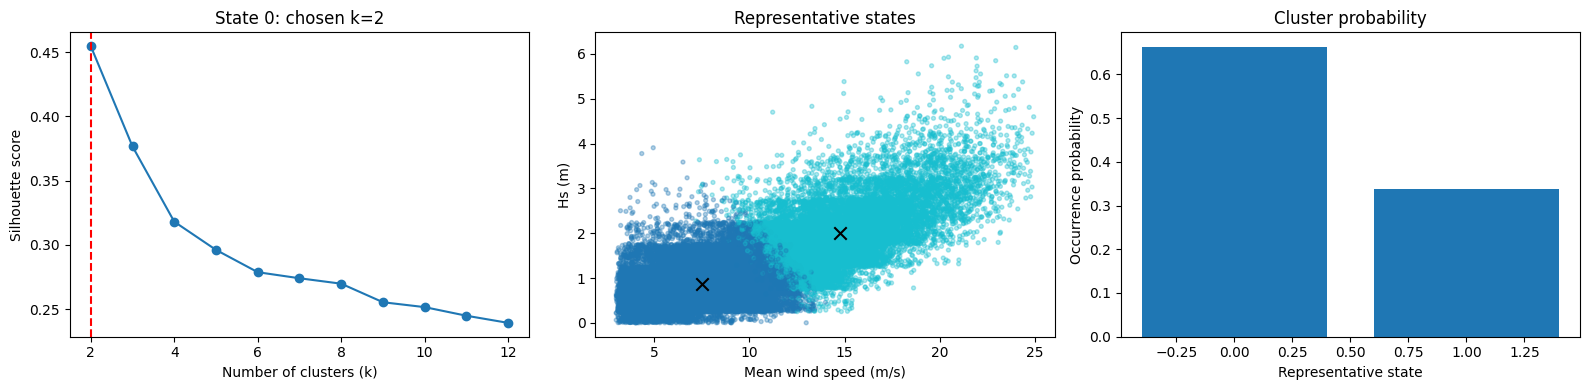

In [43]:
results_normal = cluster_operating_state(df, state=0)

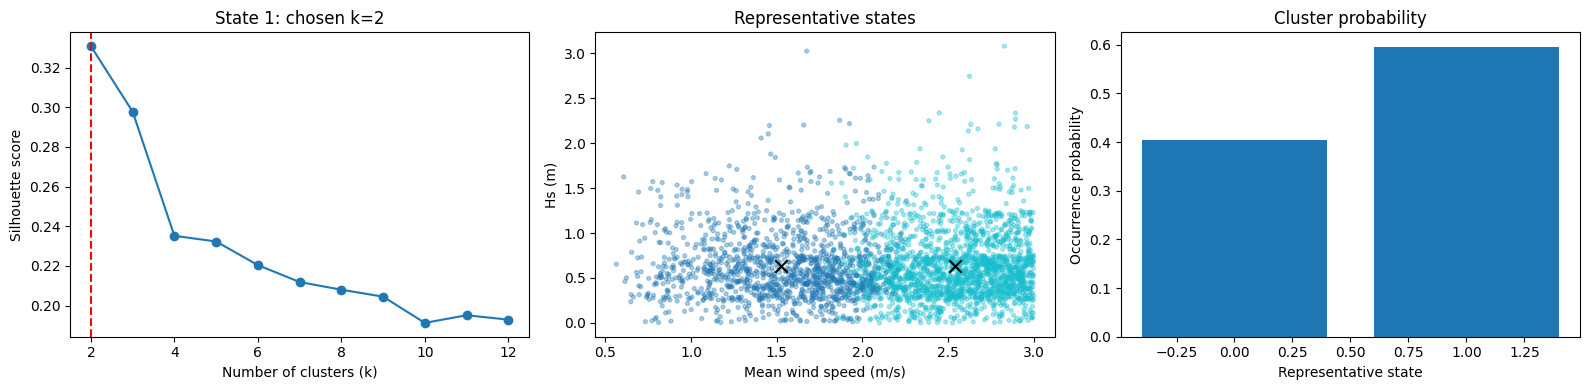

In [41]:
results_below_cutin = cluster_operating_state(df, state=1)

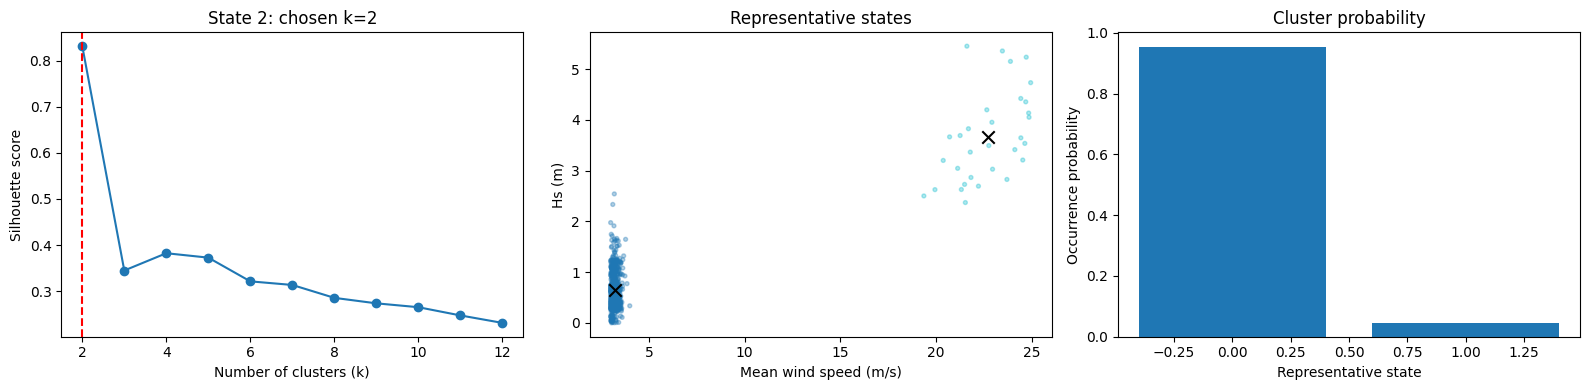

In [ ]:
results_startup = cluster_operating_state(df, state=2)

In [ ]:
results_startup = cluster_operating_state(df, state=3)

## Model 2: Gaussian Model Mixture (GMM)

In [96]:
X = df[["Hs", "Tp", "Vw_mean", "Vw_std", "RPM", "Pitch"]].copy()
scaler = StandardScaler()
features = scaler.fit_transform(X)

X1 = df[["Hs", "Tp", "Vw_mean", "Vw_std"]].copy()
X1= X1[operating_state == 0]
scaler = StandardScaler()
features1 = scaler.fit_transform(X1)

In [95]:
def gmm_component_selection(X, max_components=20, random_state=100):
    """ Select the optimal number of components for a Gaussian Mixture Model using BIC. """


    k_range = range(1, max_components + 1)
    bic = [GaussianMixture(n_components=k, random_state=random_state).fit(X).bic(X) for k in k_range]

    plt.figure(figsize=(8, 4))
    plt.plot(k_range, bic, 'o-')
    plt.xlabel('Number of components k'); plt.ylabel('BIC (lower is better)')
    plt.title('GMM component selection'); plt.grid(alpha=0.3); plt.show()

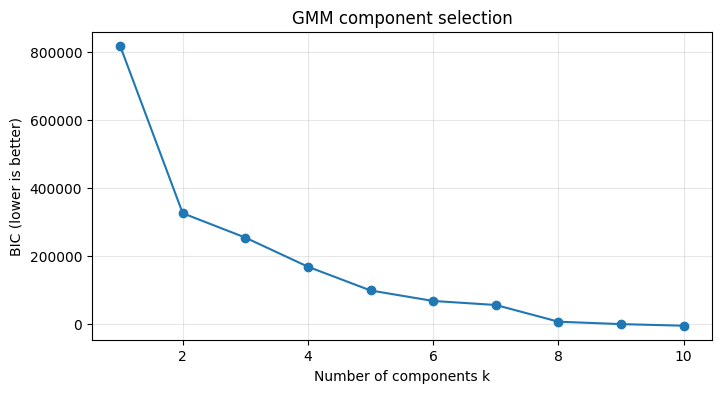

In [94]:
gmm_results_normal = gmm_component_selection(X, max_components=12, random_state=100)

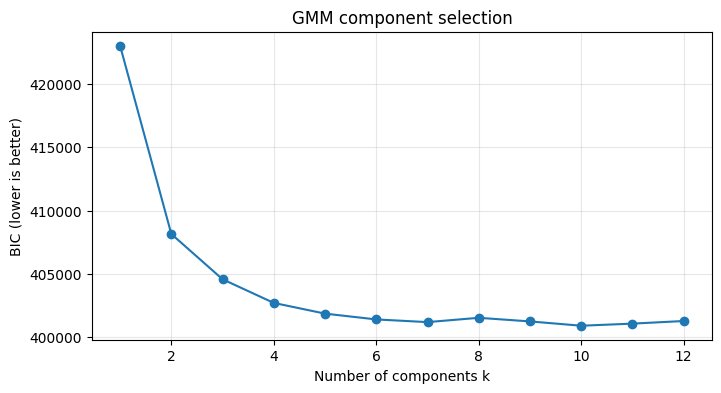

In [97]:
gmm_results_normal = gmm_component_selection(X1, max_components=12, random_state=100)

In [72]:
def cluster_operating_state_gmm(df, state, k_num, feature_columns, random_state=100, show_plots=True):

    # Keep only the requested operating state and usable feature rows
    df_state = df.loc[df["operating_state"].isin(np.atleast_1d(state))].copy()
    feature_data = (df_state[feature_columns].replace([np.inf, -np.inf], np.nan).dropna())
    df_state = df_state.loc[feature_data.index].copy()
    
    # Normalize the features
    scaler = StandardScaler()
    X = scaler.fit_transform(feature_data)

    # Run Gaussian Mixture Model clustering
    gmm = GaussianMixture(n_components=k_num, random_state=random_state)
    df_state["cluster"] = gmm.fit_predict(X)

    # Get cluster centers and occurrence probabilities
    centers = pd.DataFrame(scaler.inverse_transform(gmm.means_),columns=feature_columns,)
    centers.insert(0, "cluster", np.arange(k_num))
    probabilities = (df_state["cluster"].value_counts(normalize=True).reindex(range(k_num), fill_value=0))
    centers["occurrence_probability"] = probabilities.to_numpy()

    # Plot
    if show_plots:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        if "Vw_mean" in feature_columns and "Hs" in feature_columns:
            axes[0].scatter( df_state["Vw_mean"], df_state["Hs"], c=df_state["cluster"], s=8, alpha=0.35, cmap="tab10", ) 
            axes[0].scatter( centers["Vw_mean"], centers["Hs"], c="black", marker="x", s=70, label="GMM mean", ) 
            axes[0].set( xlabel="Mean wind speed (m/s)", ylabel="Significant wave height (m)", title=f"State {state}: {k_num} clusters")
            axes[0].legend()

        centers_sorted = centers.sort_values("Vw_mean")
        axes[1].bar(np.arange(len(centers_sorted)),centers_sorted["occurrence_probability"],)
        axes[1].set(xlabel="Representative state (sorted by wind speed)",ylabel="Occurrence probability",title="Cluster frequencies")

        plt.tight_layout()
        plt.show()

    return {
        "df_state": df_state,
        "centers": centers,
        "model": gmm,
        "scaler": scaler,
        "k_num": k_num,
    }

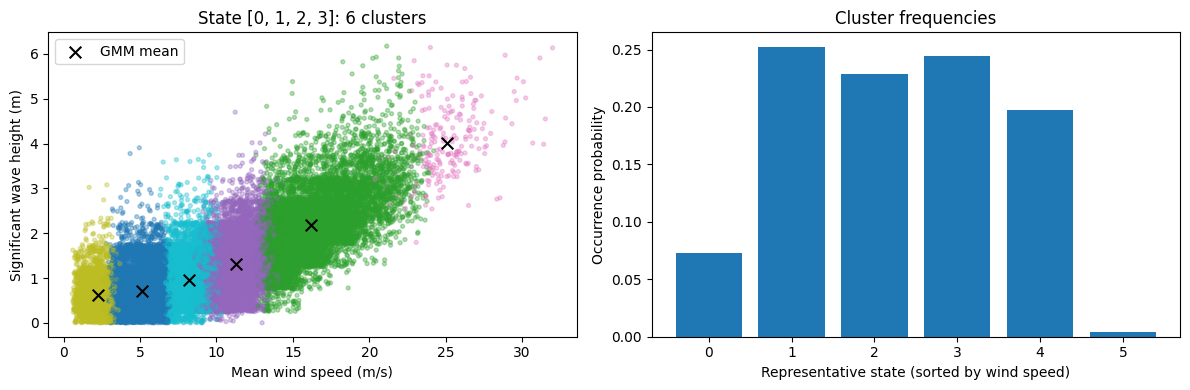

   cluster        Hs        Tp    Vw_mean    Vw_std        RPM         Pitch  \
0        0  0.719796  5.761851   5.132883  1.143685   7.540791 -1.243450e-14   
1        1  2.180034  6.956449  16.166688  2.326032  12.091403  1.061933e+01   
2        2  1.318544  5.952453  11.294420  1.854082  11.450564  1.722609e+00   
3        3  4.006145  8.849734  25.098668  3.272706   6.740532  3.021058e+01   
4        4  0.626604  6.058262   2.256759  0.727376   2.838248  4.884981e-15   
5        5  0.946446  5.621241   8.206536  1.489478   9.261396  2.136898e-04   

   occurrence_probability  
0                0.252335  
1                0.197425  
2                0.244301  
3                0.004338  
4                0.072824  
5                0.228776  


In [86]:
# Change this based on the plot!
GMM_NORM_K = 6

# Make the analysis for the normal operating state
gmm_results_normal = cluster_operating_state_gmm(df, state=[0, 1, 2, 3], k_num=GMM_NORM_K, feature_columns=feature_columns)
print(gmm_results_normal["centers"])

In [87]:
feature_columns1 = ["Hs", "Tp", "Vw_mean", "Vw_std"]
feature_columns2 = ["Hs", "Tp", "Vw_mean", "Vw_std", "RPM", "Pitch"]

# Normal operating state clustering with GMM
gmm_all_env_only = cluster_operating_state_gmm(df, state=[0, 1, 2, 3], k_num=GMM_NORM_K, feature_columns=feature_columns1, show_plots=False)
gmm_all_env_struc = cluster_operating_state_gmm(df, state=[0, 1, 2, 3], k_num=GMM_NORM_K, feature_columns=feature_columns2, show_plots=False)
gmm_norm_env_only = cluster_operating_state_gmm(df, state=[0], k_num=GMM_NORM_K, feature_columns=feature_columns1, show_plots=False)
gmm_norm_env_struc = cluster_operating_state_gmm(df, state=[0], k_num=GMM_NORM_K, feature_columns=feature_columns2, show_plots=False)


for gmm_result in [gmm_all_env_only, gmm_all_env_struc, gmm_norm_env_only, gmm_norm_env_struc]:
    clustered = gmm_result["df_state"].copy()
    clustered = clustered.dropna(subset=["DEL"])
    clustered["DEL_lumped"] = (clustered.groupby("cluster")["DEL"].transform("mean"))
    rmse = mean_squared_error(clustered["DEL"], clustered["DEL_lumped"]) ** 0.5
    r2 = r2_score(clustered["DEL"], clustered["DEL_lumped"])
    gmm_result['rmse'] = rmse
    gmm_result['r2'] = r2

# Comparison table of RMSE and R² for different clustering approaches
res = pd.DataFrame({
    "Clustering Approach": ["All states, env only", "All states, env + struc", "Normal state, env only", "Normal state, env + struc"],
    "RMSE": [gmm_all_env_only['rmse'], gmm_all_env_struc['rmse'], gmm_norm_env_only['rmse'], gmm_norm_env_struc['rmse']], 
    "R²": [gmm_all_env_only['r2'], gmm_all_env_struc['r2'], gmm_norm_env_only['r2'], gmm_norm_env_struc['r2']]
})

print(res)

         Clustering Approach           RMSE        R²
0       All states, env only  288399.928137  0.795084
1    All states, env + struc  198313.884937  0.903107
2     Normal state, env only  276395.415449  0.782405
3  Normal state, env + struc  148197.843884  0.937444


In [81]:
# Get the RMSE and R² for the lumped DEL values based on the cluster means

clustered = gmm_results_normal["df_state"].copy()
clustered = clustered.dropna(subset=["DEL"])

clustered["DEL_lumped"] = (clustered.groupby("cluster")["DEL"].transform("mean"))

rmse = mean_squared_error(clustered["DEL"], clustered["DEL_lumped"]) ** 0.5
r2 = r2_score(clustered["DEL"], clustered["DEL_lumped"])

print(f"State 0 lumping RMSE: {rmse:,.2f}")
print(f"State 0 lumping R²:   {r2:.4f}")

State 0 lumping RMSE: 238,762.40
State 0 lumping R²:   0.8596


In [61]:
clustered

,Hs,Tp,Vw_mean,Vw_std,RPM,Pitch,DEL,operating_state,DEL_lumped,cluster
0,1.248500,4.757716,9.203143,1.749217,9.972552,0.019171,1.460472e+06,0,1.522995e+06,1
1,1.574769,6.303943,11.370682,1.839102,11.694177,1.296207,1.733923e+06,0,1.522995e+06,1
2,0.895745,5.364305,11.460520,1.651695,11.757063,1.184234,1.831648e+06,0,1.522995e+06,1
3,0.638518,7.412787,6.598440,1.438964,8.256958,0.000000,8.610574e+05,0,8.545795e+05,0
4,2.740453,5.828636,15.811478,2.406468,12.093967,10.479204,2.552811e+06,0,2.074545e+06,4
...,...,...,...,...,...,...,...,...,...,...
49785,1.176367,6.106103,4.946563,0.928471,7.353955,0.000000,7.509783e+05,0,8.545795e+05,0
49786,0.392188,3.788921,6.038198,1.140180,7.792752,0.000000,7.565224e+05,0,8.263055e+05,2
49787,1.531013,6.234826,15.363955,2.396577,12.093317,10.054509,1.969823e+06,0,2.074545e+06,4
49789,0.407781,5.867851,5.879517,1.179210,7.776988,0.000000,7.234414e+05,0,8.263055e+05,2


In [62]:
cluster_summary = clustered.groupby("cluster").agg(
    Hs=("Hs", "mean"),
    Tp=("Tp", "mean"),
    Vw_mean=("Vw_mean", "mean"),
    DEL_mean=("DEL", "mean"),
    count=("DEL", "size"),
)

print(cluster_summary)

               Hs        Tp    Vw_mean      DEL_mean  count
cluster                                                    
0        1.033899  6.703150   5.849084  8.545795e+05   7797
1        1.047954  5.524969  10.164732  1.522995e+06  15015
2        0.469847  4.866983   6.063063  8.263055e+05   9376
3        3.008631  8.208031  17.439315  2.207845e+06   3250
4        1.882205  6.663495  13.901839  2.074545e+06  10348


,k,RMSE,R2
0,2,312800.981937,0.758942
1,4,264434.234401,0.827726
2,6,198313.884937,0.903107
3,8,158111.323361,0.938410
4,10,153188.628086,0.942185
5,15,140472.140192,0.951386
6,20,131452.986246,0.957428
7,30,129704.922683,0.958553
8,50,127814.962626,0.959752


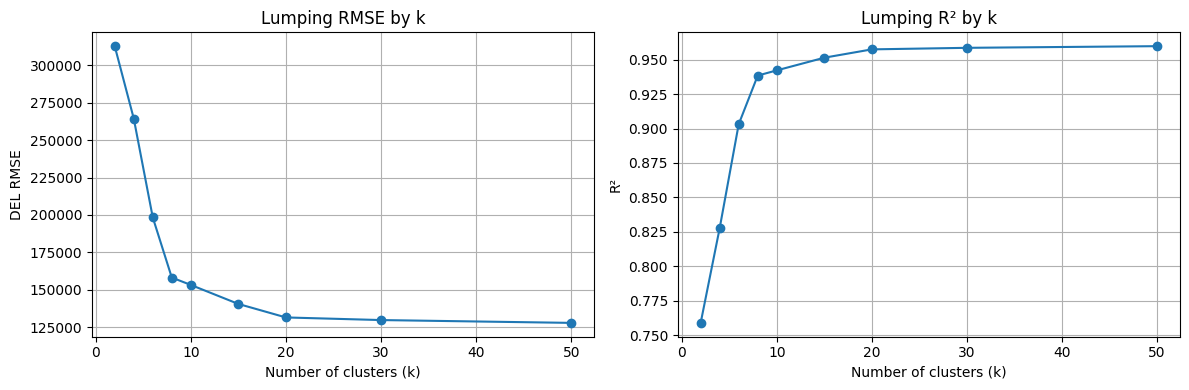

In [88]:
# can you make a plot for different k values and show the RMSE and R² for each k value
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

states = [0, 1, 2, 3]
k_values = [2, 4, 6, 8, 10, 15, 20, 30, 50]
scores = []

for k in k_values:
    result = cluster_operating_state_gmm(
        df,
        state=states,
        k_num=k,
        feature_columns=feature_columns,
        random_state=100,
        show_plots=False,
    )

    clustered = result["df_state"].dropna(subset=["DEL"]).copy()
    clustered["DEL_lumped"] = (
        clustered.groupby("cluster")["DEL"].transform("mean")
    )

    scores.append({
        "k": k,
        "RMSE": np.sqrt(mean_squared_error(
            clustered["DEL"], clustered["DEL_lumped"]
        )),
        "R2": r2_score(clustered["DEL"], clustered["DEL_lumped"]),
    })

metrics_by_k = pd.DataFrame(scores)
display(metrics_by_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(metrics_by_k["k"], metrics_by_k["RMSE"], marker="o")
axes[0].set(xlabel="Number of clusters (k)", ylabel="DEL RMSE",
            title="Lumping RMSE by k")
axes[0].grid(True)

axes[1].plot(metrics_by_k["k"], metrics_by_k["R2"], marker="o")
axes[1].set(xlabel="Number of clusters (k)", ylabel="R²",
            title="Lumping R² by k")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Method 3: DBSCAN

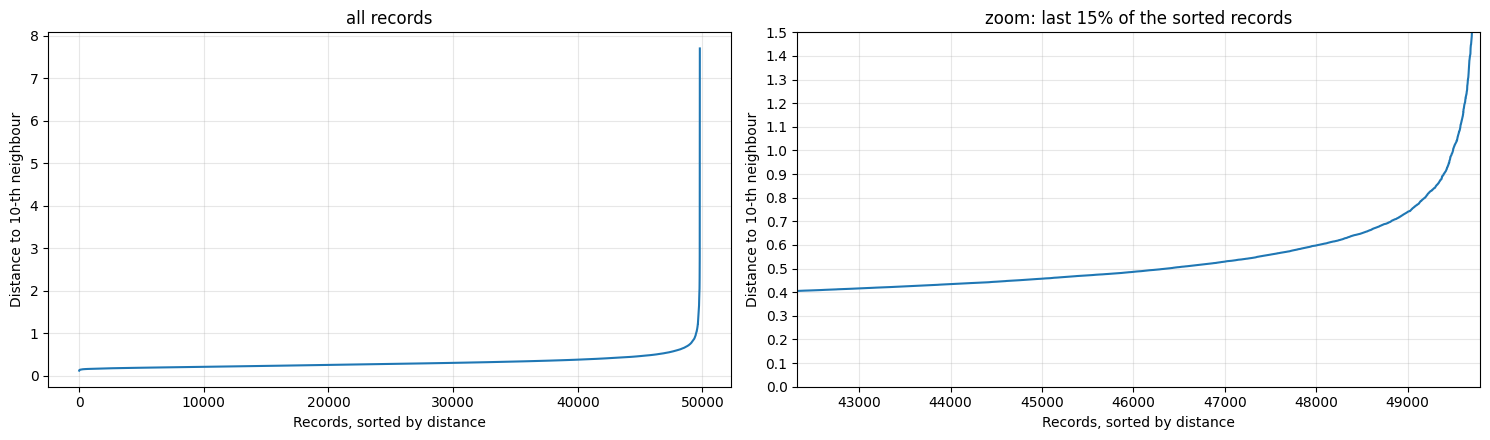

In [99]:
min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples, algorithm='kd_tree').fit(X)
distances, _ = nn.kneighbors(X)
k_dist = np.sort(distances[:, -1])        # distance to the 10th nearest neighbour (the record itself counts as the 1st)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(k_dist); ax[0].set_title('all records')
ax[1].plot(k_dist); ax[1].set_title('zoom: last 15% of the sorted records')
ax[1].set_xlim(0.85 * len(k_dist), len(k_dist)); ax[1].set_ylim(0, 1.5); ax[1].set_yticks(np.arange(0, 1.6, 0.1))
for a in ax:
    a.set_xlabel('Records, sorted by distance'); a.set_ylabel(f'Distance to {min_samples}-th neighbour'); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

,eps,n_clusters,noise_fraction,RMSE,R2
0,0.30,9,0.083830,561406.597716,0.145773
1,0.45,2,0.018517,621168.028713,0.000248
2,0.60,2,0.006025,624693.605075,0.016559
3,0.75,2,0.002591,626016.478494,0.023007
4,0.90,2,0.001044,626893.668264,0.027436


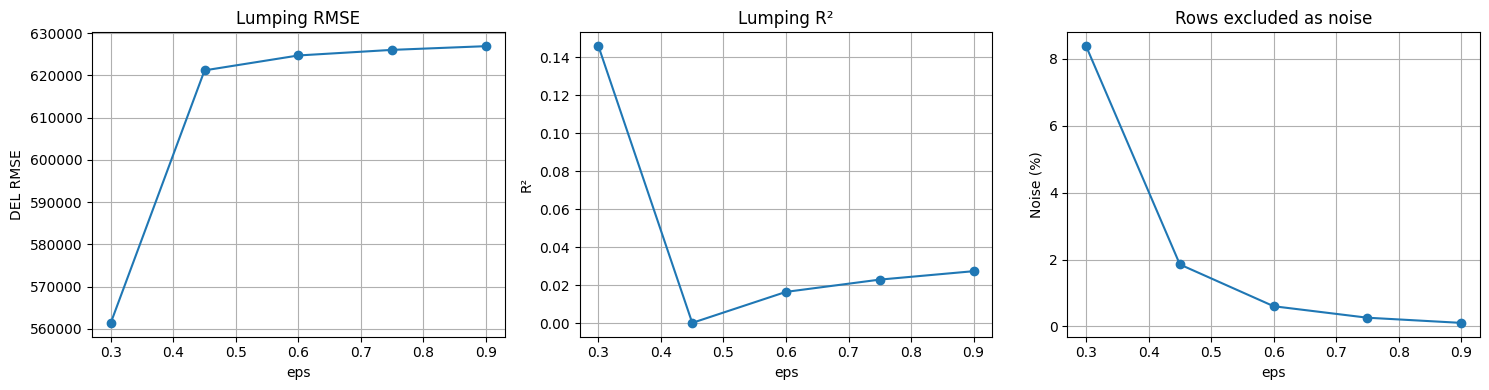

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

dbscan_features = ["Hs", "Tp", "Vw_mean", "Vw_std", "RPM", "Pitch"]
eps_values = [0.3, 0.45, 0.6, 0.75, 0.9]

# Keep your chosen min_samples value.
# Use the same rows for clustering and DEL scoring.
data = (df[dbscan_features + ["DEL"]].replace([np.inf, -np.inf], np.nan).dropna())

X_scaled = StandardScaler().fit_transform(data[dbscan_features])
scores = []

for eps in eps_values:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    is_clustered = labels != -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    scored = data.loc[is_clustered].copy()
    scored["cluster"] = labels[is_clustered]

    if len(scored) >= 2 and n_clusters > 0:
        scored["DEL_lumped"] = (
            scored.groupby("cluster")["DEL"].transform("mean")
        )
        rmse = np.sqrt(mean_squared_error(scored["DEL"], scored["DEL_lumped"]))
        r2 = r2_score(scored["DEL"], scored["DEL_lumped"])
    else:
        rmse = np.nan
        r2 = np.nan

    scores.append({
        "eps": eps,
        "n_clusters": n_clusters,
        "noise_fraction": np.mean(labels == -1),
        "RMSE": rmse,
        "R2": r2,
    })

metrics_by_eps = pd.DataFrame(scores)
display(metrics_by_eps)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(metrics_by_eps["eps"], metrics_by_eps["RMSE"], marker="o")
axes[0].set(xlabel="eps", ylabel="DEL RMSE", title="Lumping RMSE")
axes[0].grid(True)

axes[1].plot(metrics_by_eps["eps"], metrics_by_eps["R2"], marker="o")
axes[1].set(xlabel="eps", ylabel="R²", title="Lumping R²")
axes[1].grid(True)

axes[2].plot(
    metrics_by_eps["eps"],
    metrics_by_eps["noise_fraction"] * 100,
    marker="o",
)
axes[2].set(xlabel="eps", ylabel="Noise (%)", title="Rows excluded as noise")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [113]:
reference = df["operating_state"].eq(0)  # Assumes state 0 means normal operation
results = pd.DataFrame(index=df.index)
fit_time = {}

profile_cols = ["Hs", "Tp", "Vw_mean", "Vw_std", "RPM", "Pitch", "DEL"]

def _align_cluster_labels(labels, data):
    labels = np.asarray(labels)
    if labels.ndim != 1 or len(labels) != len(data):
        raise ValueError("labels must contain one label for each row in data")
    return pd.Series(labels, index=data.index, name="cluster")

def cluster_profile(labels, data=df):
    """Return cluster sizes and median values for this dataset."""
    labels = _align_cluster_labels(labels, data)
    prof = data[profile_cols].groupby(labels).median().round(2)
    sizes = labels.value_counts().reindex(prof.index).astype(int)
    prof.insert(0, "size", sizes)
    return prof

def plot_clusters(labels, title, max_clusters=16, data=df):
    """Plot selected dataset measurements by cluster; DBSCAN noise is shown in black."""
    labels = _align_cluster_labels(labels, data).to_numpy()
    sizes = pd.Series(labels[labels >= 0]).value_counts()
    main = sizes.index[:max_clusters]
    x = data["Vw_mean"].to_numpy()
    plot_specs = [
        ("Hs", "Significant wave height [m]"),
        ("RPM", "RPM"),
        ("DEL", "DEL"),
    ]
    fig, axes = plt.subplots(1, len(plot_specs), figsize=(18, 5))
    for ax, (column, ylabel) in zip(axes, plot_specs):
        y = data[column].to_numpy()
        small = (labels >= 0) & ~np.isin(labels, main)
        if small.any():
            ax.plot(x[small], y[small], ".", ms=2, color="lightgrey", label="other clusters")
        for i, cluster in enumerate(main):
            mask = labels == cluster
            ax.plot(x[mask], y[mask], ".", ms=2, color=f"C{i}", label=f"cluster {cluster} (n={mask.sum()})")
        noise = labels == -1
        if noise.any():
            ax.plot(x[noise], y[noise], "x", ms=3, color="black", label=f"noise (n={noise.sum()})")
        ax.set_xlabel("Mean wind speed [m/s]")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].legend(markerscale=5, fontsize=8, loc="best")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

def evaluate_filter(keep, name, data=df):
    """Compare a predicted normal-operation mask with operating_state == 0."""
    keep = np.asarray(keep, dtype=bool)
    if keep.ndim != 1 or len(keep) != len(data):
        raise ValueError("keep must contain one boolean for each row in data")
    actual_normal = data["operating_state"].eq(0).to_numpy()
    true_positive = int((keep & actual_normal).sum())
    precision = true_positive / keep.sum() if keep.sum() else np.nan
    recall = true_positive / actual_normal.sum() if actual_normal.sum() else np.nan
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else np.nan
    return {
        "method": name,
        "kept [%]": round(100 * keep.mean(), 1),
        "precision": round(precision, 3) if np.isfinite(precision) else np.nan,
        "recall": round(recall, 3) if np.isfinite(recall) else np.nan,
        "F1": round(f1, 3) if np.isfinite(f1) else np.nan,
    }

print(f'{reference.mean():.1%} of df rows have operating_state = 0 (the assumed normal state).')

92.0% of df rows have operating_state = 0 (the assumed normal state).


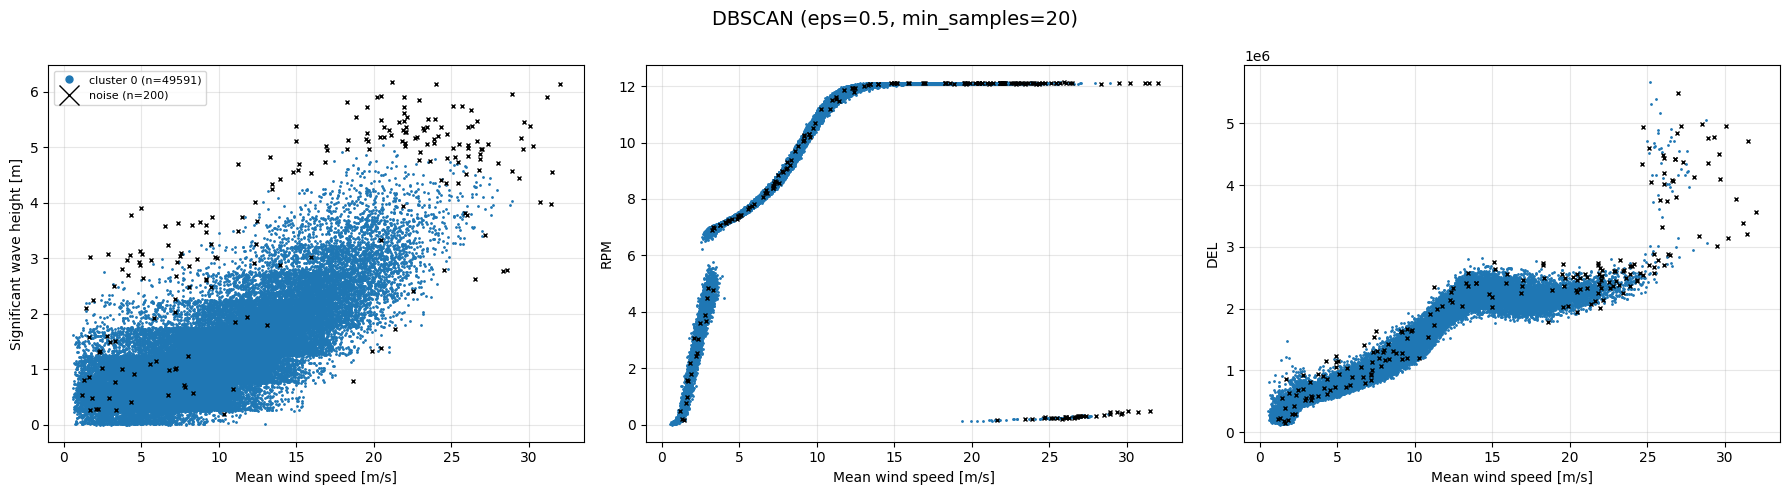

In [129]:
eps = 0.5
min_samples = 20
features = StandardScaler().fit_transform(df[["Hs", "Tp", "Vw_mean"]].replace([np.inf, -np.inf], np.nan).dropna())

dbscan_model = DBSCAN(eps=eps, min_samples=min_samples).fit(features)
dbscan_labels = dbscan_model.labels_

plot_clusters(dbscan_labels, f"DBSCAN (eps={eps}, min_samples={min_samples})", data=df,)

In [120]:
eval_dbscan = evaluate_filter(dbscan_labels >= 0, "DBSCAN", data=df)
print(f"DBSCAN: {eval_dbscan['kept [%]']:.1f}% of rows kept, precision={eval_dbscan['precision']:.3f}, recall={eval_dbscan['recall']:.3f}, F1={eval_dbscan['F1']:.3f}")

DBSCAN: 53.4% of rows kept, precision=0.959, recall=0.557, F1=0.704


In [112]:
cluster_profile(dbscan_labels, data=df)

,size,Hs,Tp,Vw_mean,Vw_std,RPM,Pitch,DEL
cluster,,,,,,,,
-1,185,3.13,9.86,15.12,2.45,10.17,9.36,2187393.10
0,49546,1.05,5.98,8.90,1.57,9.82,0.00,1253813.90
1,60,3.96,9.06,25.86,3.35,0.24,40.05,4296682.62


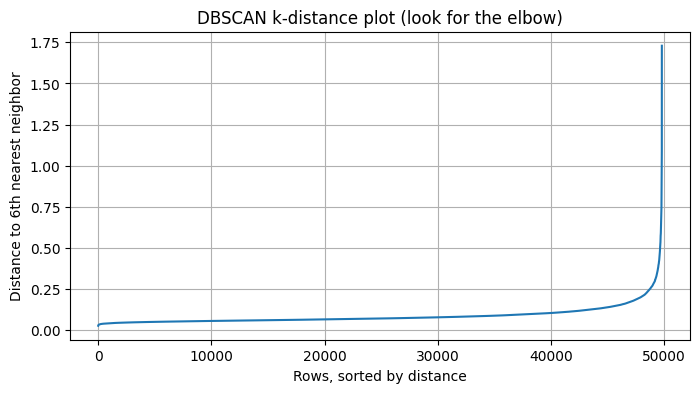

In [122]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

feature_columns = ["Hs", "Tp", "Vw_mean"]

# Keep complete rows so the feature data, DEL, and eventual labels stay aligned
data = (
    df[feature_columns + ["DEL"]]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

X_scaled = StandardScaler().fit_transform(data[feature_columns])
del_values = data["DEL"].to_numpy()

# A starting value: 2 × number of features
base_min_samples = 2 * len(feature_columns)

neighbors = NearestNeighbors(n_neighbors=base_min_samples).fit(X_scaled)
distances = neighbors.kneighbors(X_scaled)[0][:, -1]
k_distances = np.sort(distances)

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel("Rows, sorted by distance")
plt.ylabel(f"Distance to {base_min_samples}th nearest neighbor")
plt.title("DBSCAN k-distance plot (look for the elbow)")
plt.grid(True)
plt.show()

In [123]:
min_samples_values = [6, 10, 15]
quantiles = np.linspace(0.70, 0.98, 8)
score_rows = []
labels_by_params = {}

for min_samples in min_samples_values:
    neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
    distances = neighbors.kneighbors(X_scaled)[0][:, -1]
    eps_values = np.unique(np.quantile(distances, quantiles))
    eps_values = eps_values[eps_values > 0]

    for eps in eps_values:
        labels = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(X_scaled)
        keep = labels != -1
        n_clusters = len(np.unique(labels[keep]))
        labels_by_params[(min_samples, float(eps))] = labels

        if keep.any() and n_clusters > 0:
            scored = pd.DataFrame({
                "cluster": labels[keep],
                "DEL": del_values[keep],
            })
            del_lumped = scored.groupby("cluster")["DEL"].transform("mean")

            rmse = np.sqrt(mean_squared_error(scored["DEL"], del_lumped))
            r2 = r2_score(scored["DEL"], del_lumped)
        else:
            rmse = np.nan
            r2 = np.nan

        score_rows.append({
            "min_samples": min_samples,
            "eps": float(eps),
            "n_clusters": n_clusters,
            "noise_fraction": np.mean(labels == -1),
            "DEL_RMSE": rmse,
            "DEL_R2": r2,
        })

metrics = pd.DataFrame(score_rows)
display(metrics.sort_values("DEL_RMSE").head(15))

,min_samples,eps,n_clusters,noise_fraction,DEL_RMSE,DEL_R2
0,6,0.087513,224,0.206905,559843.123910,0.094457
1,6,0.092889,201,0.178004,569247.458152,0.082515
8,10,0.106939,78,0.200137,571613.751296,0.052762
2,6,0.099505,174,0.149384,577015.592891,0.075748
16,15,0.123998,28,0.198470,578797.038954,0.028101
9,10,0.113173,62,0.172722,582127.747830,0.044247
3,6,0.108255,148,0.120162,583035.600408,0.073696
17,15,0.131396,25,0.173887,586474.576389,0.022952
10,10,0.121242,53,0.146713,587050.519005,0.045503
18,15,0.140990,15,0.144986,591295.421378,0.028510


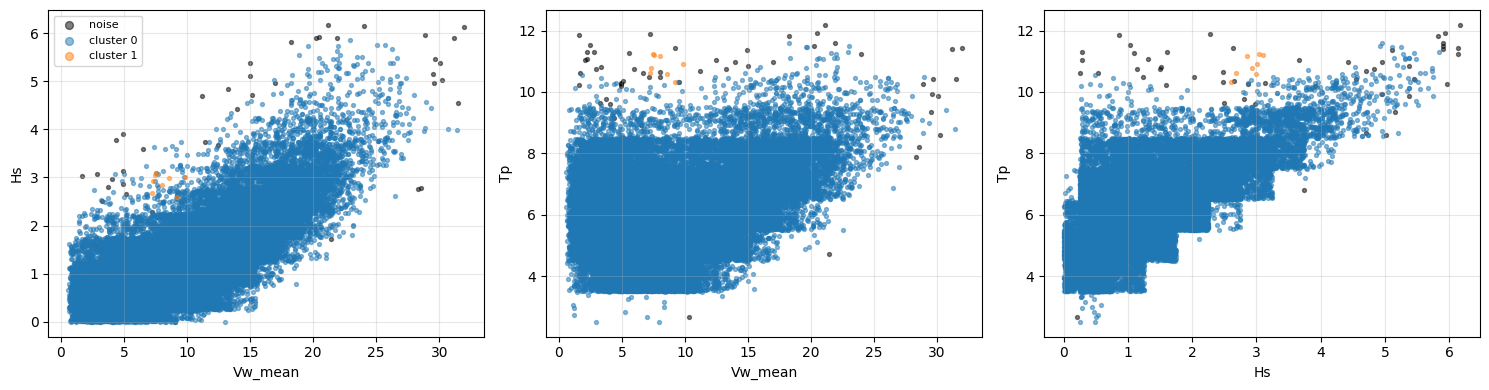

In [ ]:
selected_min_samples = 10  # replace with your chosen table value
selected_eps = 0.6         # replace with your chosen table value

final_labels = DBSCAN(eps=selected_eps, min_samples=selected_min_samples).fit_predict(X_scaled)

# Labels correspond to data.index, not necessarily every row in df
clustered_data = df.loc[data.index].copy()
clustered_data["dbscan_cluster"] = final_labels

# Pairwise views of the three features; -1 is DBSCAN noise
pairs = [("Vw_mean", "Hs"), ("Vw_mean", "Tp"), ("Hs", "Tp")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (x_col, y_col) in zip(axes, pairs):
    for cluster in np.unique(final_labels):
        mask = final_labels == cluster
        color = "black" if cluster == -1 else f"C{int(cluster) % 10}"
        name = "noise" if cluster == -1 else f"cluster {cluster}"
        ax.scatter(
            clustered_data.loc[:, x_col].to_numpy()[mask],
            clustered_data.loc[:, y_col].to_numpy()[mask],
            s=8,
            alpha=0.5,
            color=color,
            label=name,
        )
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.grid(alpha=0.3)

axes[0].legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()